# Data Cleaning

##### 1. Which months, days, and hours generate the most revenue, and how does average order value change over time?
##### 2. Which countries contribute the most to total revenue, and how does revenue distribution vary across geographic markets?


In [9]:
from pathlib import Path
import pandas as pd
import numpy as np

# Load the original workbook so this notebook can run independently.
project_dir = Path(r'E:\alchemist\task1')
excel_path = project_dir / 'Online Retail.xlsx'
retail_df = pd.read_excel(excel_path, engine='calamine')

print(f'Loaded {len(retail_df):,} original transaction rows.')

Loaded 541,909 original transaction rows.


In [15]:
for column in ['InvoiceNo', 'StockCode', 'Description', 'CustomerID', 'Country']:
    retail_df[column] = retail_df[column].astype('string')

retail_df['Description'] = retail_df['Description'].astype('string').replace({np.nan: pd.NA}) #standardize missing values in description

retail_df['Quantity'] = retail_df['Quantity'].astype('int64')

retail_df['InvoiceDate'] = pd.to_datetime(retail_df['InvoiceDate'],)

retail_df['UnitPrice'] = pd.to_numeric(retail_df['UnitPrice']).astype('float64')

# Unit selling price cannot be negative.
negative_price_rows = retail_df['UnitPrice'] < 0
print(f'Dropping {negative_price_rows.sum()} rows because UnitPrice cannot be negative.')
retail_df = retail_df.loc[~negative_price_rows].copy()

# Confirm the resulting column types and remaining missing values.
display(pd.DataFrame({
    'data_type': retail_df.dtypes,
    'missing_count': retail_df.isna().sum(),
    'missing_percent': (retail_df.isna().mean() * 100).round(2),
}))

# display(retail_df.head(10))
display(retail_df[retail_df.isna().any(axis=1)].head(15))

Dropping 0 rows because UnitPrice cannot be negative.


,data_type,missing_count,missing_percent
InvoiceNo,string,0,0.00
StockCode,string,0,0.00
Description,string,1454,0.27
Quantity,int64,0,0.00
InvoiceDate,datetime64[us],0,0.00
UnitPrice,float64,0,0.00
CustomerID,string,135078,24.93
Country,string,0,0.00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,<NA>,56,2010-12-01 11:52:00,0.00,<NA>,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,<NA>,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,<NA>,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,<NA>,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,<NA>,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,<NA>,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2010-12-01 14:32:00,2.51,<NA>,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,2010-12-01 14:32:00,0.43,<NA>,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,2010-12-01 14:32:00,0.43,<NA>,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,2010-12-01 14:32:00,0.43,<NA>,United Kingdom


In [16]:
# Derive weekday and calendar quarter from invoice timestamp
retail_df['DayofWeek'] = retail_df['InvoiceDate'].dt.day_name()
retail_df['Quarter'] = 'Q' + retail_df['InvoiceDate'].dt.quarter.astype('string')


retail_df['Revenue'] = retail_df['Quantity'] * retail_df['UnitPrice'] # UnitPrice*Quantity, Preserves negative revenue

display(retail_df[['InvoiceNo', 'InvoiceDate', 'DayofWeek', 'Quarter', 'Quantity', 'UnitPrice', 'Revenue']].head())

,InvoiceNo,InvoiceDate,DayofWeek,Quarter,Quantity,UnitPrice,Revenue
0,536365,2010-12-01 08:26:00,Wednesday,Q4,6,2.55,15.30
1,536365,2010-12-01 08:26:00,Wednesday,Q4,6,3.39,20.34
2,536365,2010-12-01 08:26:00,Wednesday,Q4,8,2.75,22.00
3,536365,2010-12-01 08:26:00,Wednesday,Q4,6,3.39,20.34
4,536365,2010-12-01 08:26:00,Wednesday,Q4,6,3.39,20.34


In [22]:
# Summarize revenue, distinct invoice count, and quantity for each country
countryrevenue_df = (
    retail_df.groupby('Country', as_index=False, dropna=False).agg(
        TotalRevenue=('Revenue', 'sum'),
        NumberOfOrders=('InvoiceNo', 'nunique'),
        TotalQuantity=('Quantity', 'sum'),
    )
    .sort_values('TotalRevenue', ascending=False, ignore_index=True)
)

display(countryrevenue_df.head(10))

,Country,TotalRevenue,NumberOfOrders,TotalQuantity
0,United Kingdom,8209930.484,23492,4263827
1,Netherlands,284661.540,101,200128
2,EIRE,263276.820,360,142637
3,Germany,221698.210,603,117448
4,France,197403.900,461,110480
5,Australia,137077.270,69,83653
6,Switzerland,56385.350,74,30325
7,Spain,54774.580,105,26824
8,Belgium,40910.960,119,23152
9,Sweden,36595.910,46,35637


In [20]:
invoice_df = (
    retail_df.groupby('InvoiceNo', dropna=False)
    .agg(
        TotalRevenue=('Revenue', 'sum'),
        InvoiceDate=('InvoiceDate', 'first'),
        Description=('Description', list),
        StockCodes=('StockCode', list),
    )
)

display(invoice_df.head())

,TotalRevenue,InvoiceDate,Description,StockCodes
InvoiceNo,,,,
536365,139.12,2010-12-01 08:26:00,"[WHITE HANGING HEART T-LIGHT HOLDER, WHITE MET...","[85123A, 71053, 84406B, 84029G, 84029E, 22752,..."
536366,22.20,2010-12-01 08:28:00,"[HAND WARMER UNION JACK, HAND WARMER RED POLKA...","[22633, 22632]"
536367,278.73,2010-12-01 08:34:00,"[ASSORTED COLOUR BIRD ORNAMENT, POPPY'S PLAYHO...","[84879, 22745, 22748, 22749, 22310, 84969, 226..."
536368,70.05,2010-12-01 08:34:00,"[JAM MAKING SET WITH JARS, RED COAT RACK PARIS...","[22960, 22913, 22912, 22914]"
536369,17.85,2010-12-01 08:35:00,[BATH BUILDING BLOCK WORD],[21756]


In [25]:
# Summarize revenue, distinct invoice count, and quantity for each stock code
stock_df = (
    retail_df.groupby('StockCode', as_index=False, dropna=False)
    .agg(
        TotalRevenue=('Revenue', 'sum'),
        NumberOfOrders=('InvoiceNo', 'nunique'),
        TotalQuantity=('Quantity', 'sum'),
    )
    .sort_values('TotalRevenue', ascending=False, ignore_index=True)
)

display(stock_df.head(10))

,StockCode,TotalRevenue,NumberOfOrders,TotalQuantity
0,DOT,206245.48,710,1707
1,22423,164762.19,2172,12980
2,47566,98302.98,1706,18022
3,85123A,97894.50,2246,38830
4,85099B,92356.03,2135,47363
5,23084,66756.59,1025,30646
6,POST,66230.64,1254,6353
7,22086,63791.94,1170,18902
8,84879,58959.73,1468,36221
9,79321,53768.06,673,10343


# Data Visualization

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Single quiet light style across both static and interactive charts.
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans', rc={
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelcolor': '#334155',
    'xtick.color': '#475569',
    'ytick.color': '#475569',
    'text.color': '#1F2937',
    'axes.titleweight': 'semibold',
})
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

PLOTLY_TEMPLATE = 'plotly_white'
PLOTLY_CONFIG = {
    'displaylogo': False,
    'modeBarButtonsToRemove': ['lasso2d', 'select2d', 'autoScale2d', 'hoverCompareCartesian', 'hoverClosestCartesian'],
}
INK = '#263746'
MUTED_BLUE = '#668596'
ACCENT = '#B66A5E'
GRID = '#E7EDF0'
WEEKDAY_ORDER = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']


# Additional calendar fields
if 'Revenue' not in retail_df.columns:
    retail_df['Revenue'] = retail_df['Quantity'] * retail_df['UnitPrice']
if 'DayofWeek' not in retail_df.columns:
    retail_df['DayofWeek'] = retail_df['InvoiceDate'].dt.day_name()
retail_df['Date'] = retail_df['InvoiceDate'].dt.normalize()
retail_df['Month'] = retail_df['InvoiceDate'].dt.month_name()
retail_df['MonthYear'] = retail_df['InvoiceDate'].dt.to_period('M')
retail_df['Hour'] = retail_df['InvoiceDate'].dt.hour

# InvoiceNo values beginning with C identify cancellations in this dataset.
cancelled_invoice_mask = retail_df['InvoiceNo'].str.upper().str.startswith('C', na=False)
return_line_mask = retail_df['Quantity'] < 0
completed_sale_mask = ~cancelled_invoice_mask & ~return_line_mask & retail_df['UnitPrice'].ge(0)

# Focused subset for charts
sales_rows = retail_df.loc[completed_sale_mask]
print(f"Completed-sale lines used in charts: {len(sales_rows):,}")
print(f"Cancellation lines excluded: {cancelled_invoice_mask.sum():,}")
print(f"Negative-quantity return lines excluded: {(return_line_mask & ~cancelled_invoice_mask).sum():,}")
print(f"Completed-sale revenue in scope: {sales_rows['Revenue'].sum():,.2f}")

# Re-aggregate only where the existing all-transaction summaries include returns/cancellations.
# One output row here means one order, not one product line.
sales_invoice_df = (
    sales_rows.groupby('InvoiceNo', as_index=False)
    .agg(
        OrderValue=('Revenue', 'sum'),
        InvoiceDate=('InvoiceDate', 'first'),
    )
)
sales_invoice_df['Date'] = sales_invoice_df['InvoiceDate'].dt.normalize()
sales_invoice_df['DayofWeek'] = sales_invoice_df['InvoiceDate'].dt.day_name()

# Pre-aggregate once at date, month, and weekday-hour levels for the requested charts.
daily_revenue_df = sales_rows.groupby('Date', as_index=False).agg(TotalRevenue=('Revenue', 'sum'))
monthly_revenue_df = sales_rows.groupby('MonthYear', as_index=False).agg(TotalRevenue=('Revenue', 'sum'))
monthly_revenue_df['Month'] = monthly_revenue_df['MonthYear'].dt.strftime('%b %Y')
weekday_order_df = (
    sales_invoice_df.groupby('DayofWeek')['InvoiceNo'].nunique()
    .reindex(WEEKDAY_ORDER, fill_value=0)
    .rename('NumberOfOrders').reset_index()
)
weekday_hour_revenue_df = (
    sales_rows.groupby(['DayofWeek', 'Hour'])['Revenue'].sum()
    .unstack(fill_value=0)
    .reindex(index=WEEKDAY_ORDER, columns=range(24), fill_value=0)
)

# Country totals are recalculated for completed sales so geographic charts share the same
# return/cancellation treatment as the time-based charts.
visual_countryrevenue_df = (
    sales_rows.groupby('Country', as_index=False)
    .agg(TotalRevenue=('Revenue', 'sum'), NumberOfOrders=('InvoiceNo', 'nunique'))
    .sort_values('TotalRevenue', ascending=False, ignore_index=True)
)
completed_revenue_total = visual_countryrevenue_df['TotalRevenue'].sum()
visual_countryrevenue_df['RevenueSharePct'] = (
    visual_countryrevenue_df['TotalRevenue'] / completed_revenue_total * 100
)


Completed-sale lines used in charts: 531,283
Cancellation lines excluded: 9,288
Negative-quantity return lines excluded: 1,336
Completed-sale revenue in scope: 10,666,684.54


## Daily Revenue Trends (Line Chart)

In [44]:
# Sum line-item revenue by calendar date before drawing  time series.
fig_daily_revenue = px.line(
    daily_revenue_df.sort_values('Date'),
    x='Date', y='TotalRevenue',
    title='Daily Revenue Trends',
    labels={'Date': 'Date', 'TotalRevenue': 'Total Daily Revenue'},
    template=PLOTLY_TEMPLATE,
    color_discrete_sequence=[MUTED_BLUE],
    custom_data=['Date'],
)
fig_daily_revenue.update_traces(
    mode='lines', line={'width': 2.5, 'shape': 'linear'},
    hovertemplate='Date: %{x|%b %d, %Y}<br>Total revenue: %{y:£,.2f}<extra></extra>',
)
fig_daily_revenue.update_layout(
    hovermode='x unified', height=430, margin={'l': 65, 'r': 25, 't': 70, 'b': 55},
    xaxis={'title': 'Date', 'showgrid': False, 'rangeslider': {'visible': True}},
    yaxis={'title': 'Total Daily Revenue', 'tickprefix': '£', 'separatethousands': True, 'gridcolor': GRID},
)
fig_daily_revenue.show(config=PLOTLY_CONFIG)


## Monthly Revenue Comparison (Bar Chart)

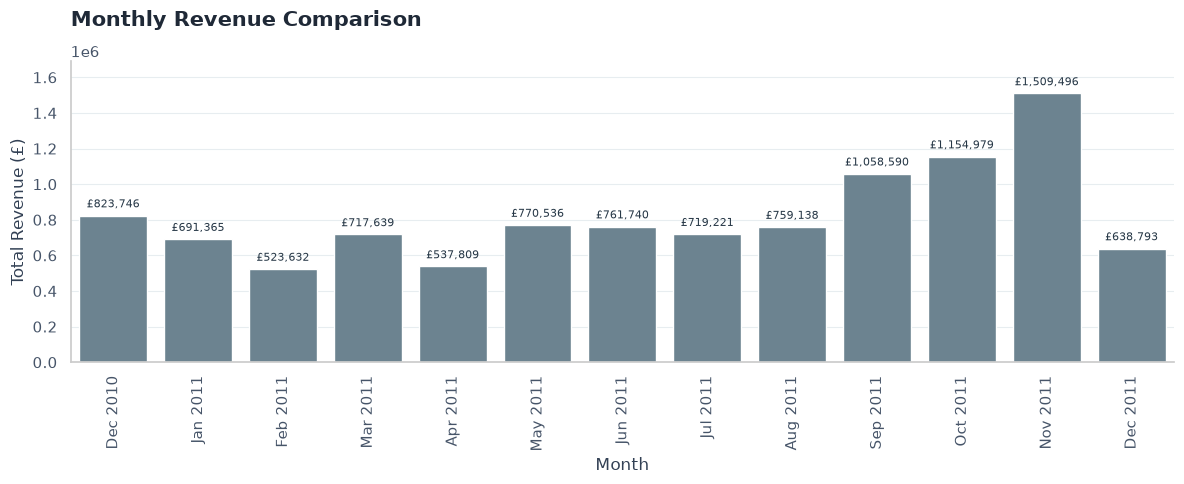

In [43]:
# MonthYear is a calendar period, so the bar order remains chronological across years.
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=monthly_revenue_df, x='Month', y='TotalRevenue', color=MUTED_BLUE, ax=ax)
ax.set_title('Monthly Revenue Comparison', loc='left', fontsize=15, pad=14)
ax.set_xlabel('Month')
ax.set_ylabel('Total Revenue (£)')
ax.tick_params(axis='x', rotation=90)
ax.grid(axis='y', color=GRID, linewidth=0.8)
ax.grid(axis='x', visible=False)
for bar in ax.patches:
    value = bar.get_height()
    ax.annotate(f'£{value:,.0f}', (bar.get_x() + bar.get_width() / 2, value),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=8, color=INK)
ax.margins(y=0.12)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


## Order Volume by Day of the Week (Bar Chart)

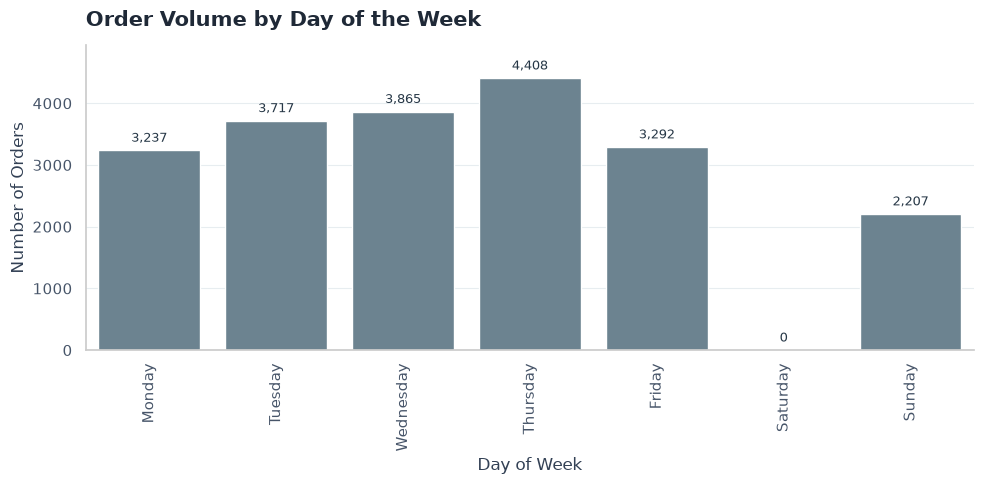

In [41]:
# Count distinct invoice IDs after making a one-row-per-invoice table.
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=weekday_order_df, x='DayofWeek', y='NumberOfOrders', color=MUTED_BLUE, ax=ax)
ax.set_title('Order Volume by Day of the Week', loc='left', fontsize=15, pad=14)
ax.set_xlabel('Day of Week')
ax.set_ylabel('Number of Orders')
ax.tick_params(axis='x', rotation=90)
ax.grid(axis='y', color=GRID, linewidth=0.8)
ax.grid(axis='x', visible=False)
for bar in ax.patches:
    value = int(bar.get_height())
    ax.annotate(f'{value:,}', (bar.get_x() + bar.get_width() / 2, value),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9, color=INK)
ax.margins(y=0.12)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


## Chart 4 — Revenue Distribution by Day and Hour (Seaborn)

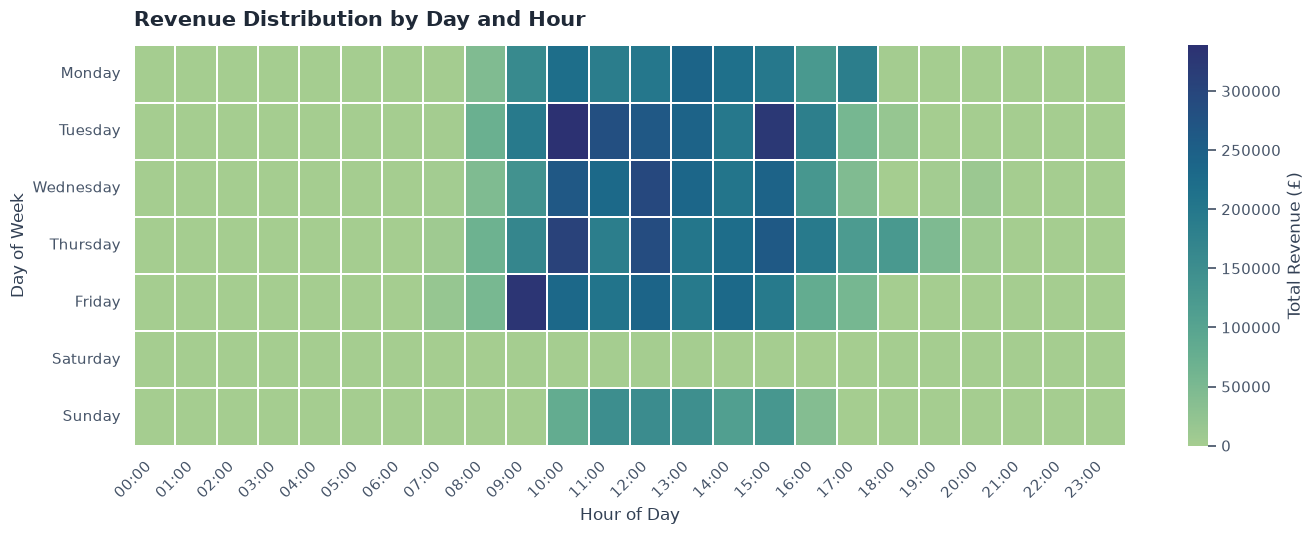

In [42]:
# Rows follow Monday-to-Sunday order and columns cover every hour, including hours with no sales.
fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(
    weekday_hour_revenue_df,
    cmap='crest',
    linewidths=0.35,
    linecolor='white',
    annot=False,
    cbar_kws={'label': 'Total Revenue (£)'},
    ax=ax,
)
ax.set_title('Revenue Distribution by Day and Hour', loc='left', fontsize=15, pad=14)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Day of Week')
ax.set_xticklabels([f'{hour:02d}:00' for hour in range(24)], rotation=45, ha='right')
fig.tight_layout()
plt.show()


## Geographic Revenue Concentration (Treemap)

In [37]:
# Rectangle area and color both encode completed-sale revenue; hover gives exact totals and share.
fig_country_treemap = px.treemap(
    visual_countryrevenue_df,
    path=['Country'], values='TotalRevenue', color='TotalRevenue',
    color_continuous_scale='Blues',
    custom_data=['TotalRevenue', 'RevenueSharePct'],
    title='Geographic Revenue Concentration',
    template=PLOTLY_TEMPLATE,
)
fig_country_treemap.update_traces(
    textinfo='label',
    hovertemplate='<b>%{label}</b><br>Total revenue: %{customdata[0]:$,.2f}'
                  '<br>Share of completed-sale revenue: %{customdata[1]:.2f}%<extra></extra>',
    tiling={'pad': 3},
)
fig_country_treemap.update_layout(
    height=650, margin={'l': 15, 'r': 15, 't': 70, 'b': 15},
    coloraxis_colorbar={'title': 'Revenue ($)', 'tickprefix': '$'},
)
fig_country_treemap.show(config=PLOTLY_CONFIG)


## Revenue Contribution by Country (Horizontol Bar Chart)

In [38]:
# All countries fit in a tall, scroll-free horizontal chart; the United Kingdom is highlighted.
country_plot_df = visual_countryrevenue_df.sort_values('TotalRevenue', ascending=False).copy()
country_plot_df['MarketColor'] = np.where(country_plot_df['Country'].eq('United Kingdom'), 'United Kingdom', 'Other countries')
country_order = country_plot_df['Country'].tolist()
country_height = max(700, 24 * len(country_plot_df) + 130)
fig_country_bar = px.bar(
    country_plot_df,
    x='TotalRevenue', y='Country', orientation='h',
    category_orders={'Country': country_order},
    color='MarketColor',
    color_discrete_map={'United Kingdom': ACCENT, 'Other countries': MUTED_BLUE},
    custom_data=['RevenueSharePct'],
    title='Revenue Contribution by Country',
    labels={'TotalRevenue': 'Total Revenue', 'Country': 'Country', 'MarketColor': 'Market'},
    template=PLOTLY_TEMPLATE,
)
fig_country_bar.update_traces(
    hovertemplate='<b>%{y}</b><br>Total revenue: %{x:$,.2f}'
                  '<br>Share of completed-sale revenue: %{customdata[0]:.2f}%<extra></extra>'
)
fig_country_bar.update_layout(
    height=country_height, showlegend=False, margin={'l': 150, 'r': 30, 't': 70, 'b': 55},
    xaxis={'title': 'Total Revenue ($)', 'tickprefix': '$', 'separatethousands': True, 'gridcolor': GRID},
    yaxis={'title': 'Country', 'categoryorder': 'array', 'categoryarray': country_order, 'autorange': 'reversed'},
)
fig_country_bar.show(config=PLOTLY_CONFIG)


# RFM Analysis & Customer Segmentation

RFM describes customer **Recency** (days since the latest purchase), **Frequency** (unique purchase invoices), and **Monetary** (net revenue). This analysis reuses the cleaned `retail_df`, its existing `Revenue` feature, and the cancellation and return flags from the visualization setup.

## 1. Prepare customer-level purchase and return data

Invoices beginning with `C` are cancellations and are excluded. Negative-quantity lines are handled separately as returns: they do not count as purchases or increase order frequency, and their refund value is subtracted from purchase revenue for Monetary. Only nonblank `CustomerID` values with at least one valid completed purchase invoice receive RFM metrics. Product lines are consolidated to customer-invoice level before frequency is calculated.

In [45]:
from IPython.display import display, Markdown

# Require a nonblank customer ID and invoice number for customer purchase metrics.
rfm_valid_customer_mask = (
    retail_df['CustomerID'].notna()
    & retail_df['CustomerID'].str.strip().ne('').fillna(False)
)
rfm_valid_invoice_mask = (
    retail_df['InvoiceNo'].notna()
    & retail_df['InvoiceNo'].str.strip().ne('').fillna(False)
)
rfm_cancelled_mask = cancelled_invoice_mask
rfm_return_mask = return_line_mask & ~rfm_cancelled_mask & retail_df['UnitPrice'].ge(0)
rfm_completed_sale_mask = (
    ~rfm_cancelled_mask
    & retail_df['Quantity'].gt(0)
    & retail_df['UnitPrice'].ge(0)
)

# Only positive, non-cancelled sales with valid customer and invoice IDs enter purchase metrics.
rfm_purchase_line_mask = (
    rfm_completed_sale_mask & rfm_valid_customer_mask & rfm_valid_invoice_mask
)
rfm_purchase_lines = retail_df.loc[rfm_purchase_line_mask]

# Consolidate product lines into one row per customer invoice before counting orders.
rfm_purchase_invoice_df = (
    rfm_purchase_lines.groupby(['CustomerID', 'InvoiceNo'], as_index=False)
    .agg(PurchaseRevenue=('Revenue', 'sum'), InvoiceDate=('InvoiceDate', 'max'))
)
customer_purchase_metrics_df = (
    rfm_purchase_invoice_df.groupby('CustomerID', as_index=False)
    .agg(
        LastPurchaseDate=('InvoiceDate', 'max'),
        Frequency=('InvoiceNo', 'nunique'),
        PurchaseRevenue=('PurchaseRevenue', 'sum'),
    )
)

# Attribute non-cancelled return value to valid customer IDs, separately from purchases.
# Since a return line's Revenue is negative, negate it to get a positive refund to subtract.
rfm_return_lines = retail_df.loc[
    rfm_return_mask & rfm_valid_customer_mask, ['CustomerID', 'Revenue']
].copy()
rfm_return_lines['ReturnValue'] = -rfm_return_lines['Revenue']
return_by_customer_df = (
    rfm_return_lines.groupby('CustomerID', as_index=False)
    .agg(ReturnedValue=('ReturnValue', 'sum'), ReturnLineCount=('ReturnValue', 'size'))
)

# Returns alone cannot provide purchase Recency or Frequency, so report such customers separately.
purchase_customer_ids = set(customer_purchase_metrics_df['CustomerID'])
return_only_customers_df = return_by_customer_df.loc[
    ~return_by_customer_df['CustomerID'].isin(purchase_customer_ids)
]

# Use the day after the latest valid completed transaction as the Recency reference date.
# Valid sales without a CustomerID still establish the dataset's latest transaction date.
reference_purchase_dates = retail_df.loc[
    rfm_completed_sale_mask & rfm_valid_invoice_mask, 'InvoiceDate'
]
rfm_reference_date = reference_purchase_dates.max().normalize() + pd.Timedelta(days=1)

customer_rfm_df = customer_purchase_metrics_df.merge(
    return_by_customer_df[['CustomerID', 'ReturnedValue']],
    on='CustomerID', how='left', validate='one_to_one',
)
customer_rfm_df['ReturnedValue'] = customer_rfm_df['ReturnedValue'].fillna(0.0)
customer_rfm_df['Recency'] = (
    rfm_reference_date - customer_rfm_df['LastPurchaseDate'].dt.normalize()
).dt.days.astype('int64')
customer_rfm_df['Monetary'] = (
    customer_rfm_df['PurchaseRevenue'] - customer_rfm_df['ReturnedValue']
)
customer_rfm_df = customer_rfm_df[
    ['CustomerID', 'Recency', 'Frequency', 'Monetary']
].sort_values('CustomerID', ignore_index=True)

# Make exclusions and separately accounted return values visible instead of silently dropping them.
rfm_returns_for_customers = return_by_customer_df[
    return_by_customer_df['CustomerID'].isin(purchase_customer_ids)
]
rfm_handling_summary_df = pd.DataFrame([
    ('Rows available after documented cleaning', len(retail_df), np.nan),
    ('Negative UnitPrice rows removed in cleaning', int(negative_price_rows.sum()), np.nan),
    ('Cancellation rows excluded', int(rfm_cancelled_mask.sum()), np.nan),
    ('Unique cancellation invoices excluded', int(retail_df.loc[rfm_cancelled_mask, 'InvoiceNo'].nunique()), np.nan),
    ('Non-cancelled negative-quantity return lines identified', int(rfm_return_mask.sum()), np.nan),
    ('Return lines and value subtracted for RFM customers', int(rfm_returns_for_customers['ReturnLineCount'].sum()), float(rfm_returns_for_customers['ReturnedValue'].sum())),
    ('Return lines without a valid CustomerID; value not attributable', int((rfm_return_mask & ~rfm_valid_customer_mask).sum()), float((-retail_df.loc[rfm_return_mask & ~rfm_valid_customer_mask, 'Revenue']).sum())),
    ('Return-only customers without a purchase; excluded from RFM', int(len(return_only_customers_df)), float(return_only_customers_df['ReturnedValue'].sum())),
    ('Positive sales lines missing CustomerID; excluded from RFM', int((rfm_completed_sale_mask & ~rfm_valid_customer_mask).sum()), float(retail_df.loc[rfm_completed_sale_mask & ~rfm_valid_customer_mask, 'Revenue'].sum())),
    ('Positive sales lines missing InvoiceNo; excluded from RFM', int((rfm_completed_sale_mask & rfm_valid_customer_mask & ~rfm_valid_invoice_mask).sum()), float(retail_df.loc[rfm_completed_sale_mask & rfm_valid_customer_mask & ~rfm_valid_invoice_mask, 'Revenue'].sum())),
    ('Zero-quantity lines; neither purchase nor return', int(retail_df['Quantity'].eq(0).sum()), 0.0),
    ('Valid customer purchase invoices in RFM', len(rfm_purchase_invoice_df), float(rfm_purchase_invoice_df['PurchaseRevenue'].sum())),
], columns=['Handling item', 'Rows / customers / invoices', 'Value (£), when relevant'])
print(f'RFM reference date: {rfm_reference_date:%Y-%m-%d}')
display(rfm_handling_summary_df.style.format({'Value (£), when relevant': '£{:,.2f}'}))

# Display one row per customer and descriptive statistics for the three RFM metrics.
display(customer_rfm_df.head(10))
rfm_metric_stats_df = customer_rfm_df[['Recency', 'Frequency', 'Monetary']].describe().T
display(
    rfm_metric_stats_df
    .style.format('£{:,.2f}', subset=pd.IndexSlice[['Monetary'], :])
    .format('{:,.2f}', subset=pd.IndexSlice[['Recency', 'Frequency'], :])
)


RFM reference date: 2011-12-10


,Handling item,Rows / customers / invoices,"Value (£), when relevant"
0,Rows available after documented cleaning,541907,£nan
1,Negative UnitPrice rows removed in cleaning,2,£nan
2,Cancellation rows excluded,9288,£nan
3,Unique cancellation invoices excluded,3836,£nan
4,Non-cancelled negative-quantity return lines identified,1336,£nan
5,Return lines and value subtracted for RFM customers,0,£0.00
6,Return lines without a valid CustomerID; value not attributable,1336,£0.00
7,Return-only customers without a purchase; excluded from RFM,0,£0.00
8,Positive sales lines missing CustomerID; excluded from RFM,133359,"£1,755,276.64"
9,Positive sales lines missing InvoiceNo; excluded from RFM,0,£0.00


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40
5,12352.0,37,8,2506.04
6,12353.0,205,1,89.00
7,12354.0,233,1,1079.40
8,12355.0,215,1,459.40
9,12356.0,23,3,2811.43


,count,mean,std,min,25%,50%,75%,max
Recency,"4,339.00",93.04,100.01,1.00,18.00,51.00,142.50,374.00
Frequency,"4,339.00",4.27,7.71,1.00,1.00,2.00,5.00,210.00
Monetary,"£4,339.00","£2,053.79","£8,988.25",£0.00,£307.25,£674.45,"£1,661.64","£280,206.02"


## 2. Assign quintile-based RFM scores

Each metric receives a score from 1 to 5. Recency is reversed so fewer days since purchase earns a higher score. Frequency and Monetary scores increase with the metric. Average percentile ranks keep tied customers together; when a metric has no variation, all customers receive a neutral score of 3 because the data cannot distinguish them on that metric.

In [46]:
def rfm_quintile_score(values, higher_is_better=True):
    """Map a numeric customer metric to a 1-5 percentile score, preserving ties."""
    if values.nunique(dropna=True) <= 1:
        return pd.Series(3, index=values.index, dtype='int64')
    percentile_rank = values.rank(method='average', ascending=True, pct=True)
    ascending_score = np.ceil(percentile_rank * 5).clip(1, 5).astype('int64')
    return ascending_score if higher_is_better else (6 - ascending_score).astype('int64')

customer_rfm_df['R_Score'] = rfm_quintile_score(customer_rfm_df['Recency'], higher_is_better=False)
customer_rfm_df['F_Score'] = rfm_quintile_score(customer_rfm_df['Frequency'], higher_is_better=True)
customer_rfm_df['M_Score'] = rfm_quintile_score(customer_rfm_df['Monetary'], higher_is_better=True)
customer_rfm_df['RFM_Score'] = (
    customer_rfm_df['R_Score'].astype('string')
    + customer_rfm_df['F_Score'].astype('string')
    + customer_rfm_df['M_Score'].astype('string')
)

# Confirm every customer received one valid score for each metric.
assert customer_rfm_df[['R_Score', 'F_Score', 'M_Score']].notna().all().all()
assert customer_rfm_df[['R_Score', 'F_Score', 'M_Score']].isin([1, 2, 3, 4, 5]).all().all()
print(f"Scored {len(customer_rfm_df):,} customers; score values range from 1 through 5.")
display(customer_rfm_df.head(10))


Scored 4,339 customers; score values range from 1 through 5.


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,1,77183.60,1,1,5,115
1,12347.0,3,7,4310.00,5,5,5,555
2,12348.0,76,4,1797.24,2,4,4,244
3,12349.0,19,1,1757.55,4,1,4,414
4,12350.0,311,1,334.40,1,1,2,112
5,12352.0,37,8,2506.04,3,5,5,355
6,12353.0,205,1,89.00,1,1,1,111
7,12354.0,233,1,1079.40,1,1,4,114
8,12355.0,215,1,459.40,1,1,2,112
9,12356.0,23,3,2811.43,4,3,5,435


## 3. Assign business segments

Rules are applied in priority order so each RFM customer receives one segment: Champions, Loyal Customers, Potential Loyalists, At Risk, Hibernating, then Regular Customers. At Risk is checked before Hibernating when both rules could apply (low Frequency but higher Monetary).

In [49]:
RFM_SEGMENT_ORDER = [
    'Champions', 'Loyal Customers', 'Potential Loyalists',
    'At Risk', 'Hibernating', 'Regular Customers',
]
r_score = customer_rfm_df['R_Score']
f_score = customer_rfm_df['F_Score']
m_score = customer_rfm_df['M_Score']
segment_conditions = [
    (r_score >= 4) & (f_score >= 4) & (m_score >= 4),
    (f_score >= 4) & (r_score >= 3),
    (r_score >= 4) & f_score.between(2, 3),
    (r_score <= 2) & ((f_score >= 3) | (m_score >= 3)),
    (r_score <= 2) & (f_score <= 2),
]
customer_rfm_df['Segment'] = np.select(
    segment_conditions,
    ['Champions', 'Loyal Customers', 'Potential Loyalists', 'At Risk', 'Hibernating'],
    default='Regular Customers',
)
customer_rfm_df['Segment'] = pd.Categorical(
    customer_rfm_df['Segment'], categories=RFM_SEGMENT_ORDER, ordered=True
)
assert customer_rfm_df['Segment'].notna().all()
assert customer_rfm_df['CustomerID'].is_unique

segment_summary_df = (
    customer_rfm_df.groupby('Segment', observed=True)
    .agg(CustomerCount=('CustomerID', 'nunique'), TotalMonetary=('Monetary', 'sum'))
    .reindex(RFM_SEGMENT_ORDER, fill_value=0)
    .rename_axis('Segment').reset_index()
)
customer_count_total = segment_summary_df['CustomerCount'].sum()
customer_revenue_total = customer_rfm_df['Monetary'].sum()
segment_summary_df['CustomerPct'] = segment_summary_df['CustomerCount'] / customer_count_total * 100
segment_summary_df['RevenuePct'] = (
    segment_summary_df['TotalMonetary'] / customer_revenue_total * 100
    if customer_revenue_total != 0 else np.nan
)

print('Final RFM DataFrame:')
display(customer_rfm_df.head(10))
print('Customer counts and net monetary contribution by segment:')
display(segment_summary_df.style.format({
    'CustomerCount': '{:,.0f}', 'CustomerPct': '{:.1f}%',
    'TotalMonetary': '£{:,.2f}', 'RevenuePct': '{:.1f}%',
}))


Final RFM DataFrame:


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,5,115,At Risk
1,12347,3,7,4310.00,5,5,5,555,Champions
2,12348,76,4,1797.24,2,4,4,244,At Risk
3,12349,19,1,1757.55,4,1,4,414,Regular Customers
4,12350,311,1,334.40,1,1,2,112,Hibernating
5,12352,37,8,2506.04,3,5,5,355,Loyal Customers
6,12353,205,1,89.00,1,1,1,111,Hibernating
7,12354,233,1,1079.40,1,1,4,114,At Risk
8,12355,215,1,459.40,1,1,2,112,Hibernating
9,12356,23,3,2811.43,4,3,5,435,Potential Loyalists


Customer counts and net monetary contribution by segment:


,Segment,CustomerCount,TotalMonetary,CustomerPct,RevenuePct
0,Champions,911,"£5,688,406.20",21.0%,63.8%
1,Loyal Customers,381,"£826,118.57",8.8%,9.3%
2,Potential Loyalists,484,"£586,236.63",11.2%,6.6%
3,At Risk,936,"£1,163,799.47",21.6%,13.1%
4,Hibernating,791,"£178,824.76",18.2%,2.0%
5,Regular Customers,836,"£468,022.27",19.3%,5.3%


## 4. RFM visualizations

These charts compare segment size and average segment scores using the same light background and muted palette as the earlier notebook charts.

### Chart 1 — Customer Distribution Across RFM Segments

findfont: Failed to find font weight semibold for Arial, now using 700.


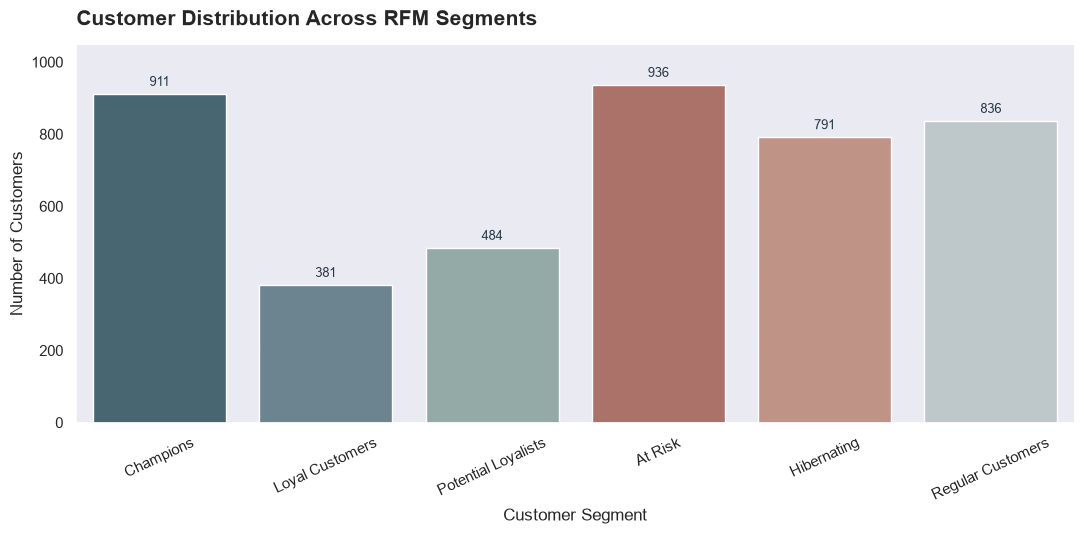

In [50]:
RFM_SEGMENT_COLORS = {
    'Champions': '#416978', 'Loyal Customers': '#668596',
    'Potential Loyalists': '#8FAEAA', 'At Risk': '#B66A5E',
    'Hibernating': '#C98E7E', 'Regular Customers': '#BCC8CC',
}
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(
    data=segment_summary_df, x='Segment', y='CustomerCount',
    order=RFM_SEGMENT_ORDER, hue='Segment', hue_order=RFM_SEGMENT_ORDER,
    palette=RFM_SEGMENT_COLORS, legend=False, ax=ax,
)
ax.set_title('Customer Distribution Across RFM Segments', loc='left', fontsize=15, pad=14)
ax.set_xlabel('Customer Segment')
ax.set_ylabel('Number of Customers')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', color=GRID, linewidth=0.8)
ax.grid(axis='x', visible=False)
for bar in ax.patches:
    if bar.get_height() > 0:
        ax.annotate(f'{int(bar.get_height()):,}',
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 4), textcoords='offset points', ha='center', va='bottom',
                    fontsize=9, color=INK)
ax.margins(y=0.12)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


### Average RFM Scores Across Customer Segments (Heatmap)

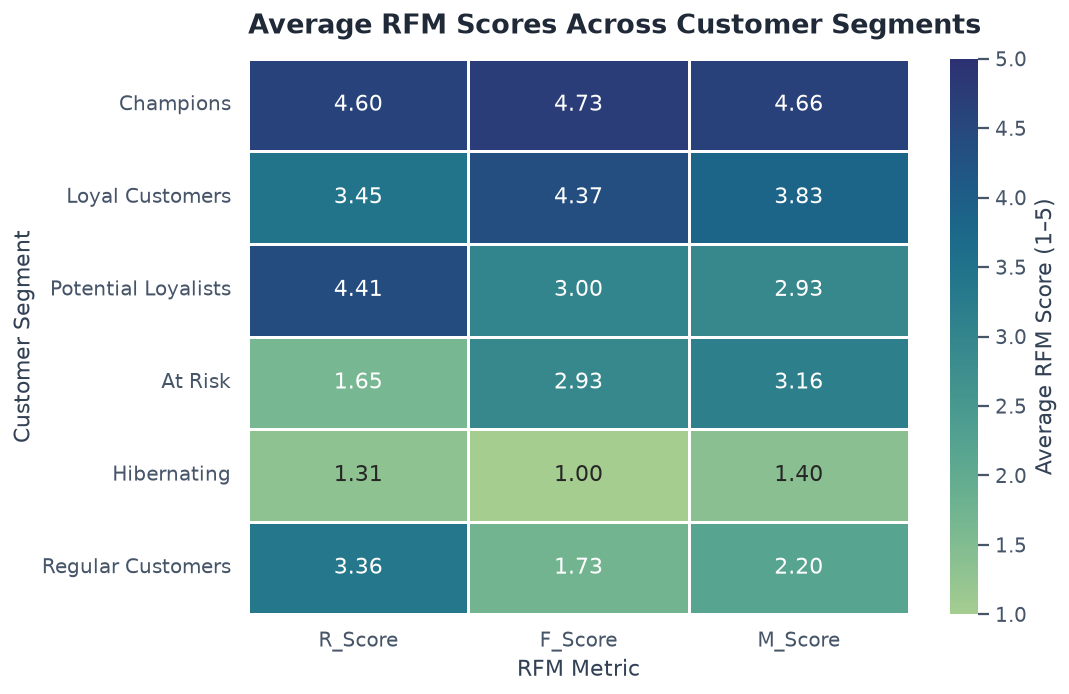

In [49]:
segment_score_means_df = (
    customer_rfm_df.groupby('Segment', observed=True)[['R_Score', 'F_Score', 'M_Score']]
    .mean().reindex(RFM_SEGMENT_ORDER)
)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.heatmap(
    segment_score_means_df,
    annot=True, fmt='.2f', cmap='crest', vmin=1, vmax=5,
    linewidths=0.6, linecolor='white',
    cbar_kws={'label': 'Average RFM Score (1–5)'}, ax=ax,
)
ax.set_title('Average RFM Scores Across Customer Segments', loc='left', fontsize=15, pad=14)
ax.set_xlabel('RFM Metric')
ax.set_ylabel('Customer Segment')
fig.tight_layout()
plt.show()


## RFM Business Insights

The RFM calculations were run on the cleaned workbook. The following observations come from those calculated results. The dynamic insight cell below will refresh them if the data changes.

- **Largest segment by customer count:** At Risk, with **936 customers (21.6%)**.
- **Largest net-revenue contribution:** Champions, with **£5,688,406.20**, or **63.8%** of net revenue for the RFM customer population.
- **Smaller segment with above-share revenue contribution:** Loyal Customers are **8.8%** of customers and contribute **9.3%** of RFM net revenue. This is a modest over-index, while Champions contribute a much larger revenue share overall.
- **At Risk and Hibernating together:** **1,727 customers (39.8%)**.
- **RFM population and returns:** 4,339 customers had valid completed purchases. There were 1,336 non-cancelled negative-quantity lines; all lacked a valid CustomerID, so they could not be attributed to an RFM customer. Their recorded return value totals £0.00, so no return amount was subtracted from customer Monetary in this run. The results also exclude 133,359 positive-sale lines without CustomerID, representing £1,755,276.64 in sales; these lines are reported but cannot be assigned to customer segments.

### Practical marketing and retention actions

- **Champions (911 customers; 63.8% of net revenue):** protect this high-value group with reliable service, VIP benefits, early access, and relevant referral offers.
- **Loyal Customers (381; 9.3%):** reinforce repeat purchasing with loyalty rewards, replenishment reminders, and relevant bundles.
- **Potential Loyalists (484; 6.6%):** encourage a second or next purchase with timely recommendations and a focused offer.
- **At Risk (936; 13.1%):** prioritize a measured win-back campaign using prior purchase context; monitor response before increasing incentives.
- **Hibernating (791; 2.0%):** use low-cost reactivation tests and limit repeated spend on nonresponders.
- **Regular Customers (836; 5.3%):** nurture with product discovery and cross-sell suggestions, then track changes in frequency.

Segment revenue percentages use net Monetary among the 4,339 customers with valid purchase history. Return-only customers and sales without a valid CustomerID are reported separately, not silently assigned to a segment.

In [51]:
# Derive the requested observations from the actual segment summary.
nonempty_segments_df = segment_summary_df.loc[segment_summary_df['CustomerCount'] > 0].copy()
max_segment_count = nonempty_segments_df['CustomerCount'].max()
largest_segments = nonempty_segments_df.loc[
    nonempty_segments_df['CustomerCount'] == max_segment_count, 'Segment'
].astype(str).tolist()
max_segment_revenue = nonempty_segments_df['TotalMonetary'].max()
top_revenue_segments = nonempty_segments_df.loc[
    nonempty_segments_df['TotalMonetary'] == max_segment_revenue, 'Segment'
].astype(str).tolist()

# Identify below-average-size segments whose share of net revenue exceeds their customer share.
equal_customer_share = 100 / len(nonempty_segments_df) if len(nonempty_segments_df) else np.nan
disproportionate_segments_df = nonempty_segments_df.loc[
    (nonempty_segments_df['CustomerPct'] < equal_customer_share)
    & (nonempty_segments_df['RevenuePct'] > nonempty_segments_df['CustomerPct'])
]
at_risk_count = int(customer_rfm_df['Segment'].eq('At Risk').sum())
hibernating_count = int(customer_rfm_df['Segment'].eq('Hibernating').sum())
at_risk_pct = at_risk_count / len(customer_rfm_df) * 100 if len(customer_rfm_df) else 0
hibernating_pct = hibernating_count / len(customer_rfm_df) * 100 if len(customer_rfm_df) else 0
top_revenue_pct = max_segment_revenue / customer_revenue_total * 100 if customer_revenue_total else np.nan

segment_actions = {
    'Champions': 'Reward with VIP benefits, early access, and referral offers while protecting the experience that keeps them active.',
    'Loyal Customers': 'Encourage repeat purchases with loyalty points, replenishment reminders, and relevant product bundles.',
    'Potential Loyalists': 'Use a timely second-purchase offer and product recommendations to build a repeat-purchase habit.',
    'At Risk': 'Run targeted win-back outreach with recent product context and a clear, time-limited reason to return.',
    'Hibernating': 'Test a low-cost reactivation message; suppress customers who do not respond to avoid wasting campaign spend.',
    'Regular Customers': 'Nurture with useful product discovery and cross-sell campaigns, then monitor whether frequency improves.',
}
if disproportionate_segments_df.empty:
    concentration_text = 'No segment was below an equal customer split while also exceeding its own share in net revenue.'
else:
    concentration_text = '; '.join(
        f'{row.Segment}: {row.CustomerPct:.1f}% of customers contribute {row.RevenuePct:.1f}% of net revenue'
        for row in disproportionate_segments_df.itertuples()
    )
action_lines = chr(10).join(
    f'- **{row.Segment}:** {segment_actions[str(row.Segment)]} '
    f'Current size: {int(row.CustomerCount):,} customers; '
    f'net revenue: £{row.TotalMonetary:,.2f} ({row.RevenuePct:.1f}%).'
    for row in nonempty_segments_df.itertuples()
)
insight_markdown = chr(10).join([
    '### Findings from this run',
    '',
    f'- **Largest segment:** {", ".join(largest_segments)} ({int(max_segment_count):,} customers per listed segment).',
    f'- **Largest net-revenue contribution:** {", ".join(top_revenue_segments)} (£{max_segment_revenue:,.2f}; {top_revenue_pct:.1f}% of RFM-customer net revenue).',
    f'- **Smaller segments with above-share revenue contribution:** {concentration_text}',
    f'- **At Risk and Hibernating:** {at_risk_count:,} At Risk ({at_risk_pct:.1f}%) and {hibernating_count:,} Hibernating ({hibernating_pct:.1f}%), {at_risk_count + hibernating_count:,} combined.',
    '',
    '### Practical marketing and retention actions',
    '',
    action_lines,
    '',
    'Revenue shares use net Monetary for customers with at least one valid purchase. Return-only customers are reported separately and do not receive RFM scores because purchase Recency and Frequency cannot be calculated for them.',
])
display(Markdown(insight_markdown))


### Findings from this run

- **Largest segment:** At Risk (936 customers per listed segment).
- **Largest net-revenue contribution:** Champions (£5,688,406.20; 63.8% of RFM-customer net revenue).
- **Smaller segments with above-share revenue contribution:** Loyal Customers: 8.8% of customers contribute 9.3% of net revenue
- **At Risk and Hibernating:** 936 At Risk (21.6%) and 791 Hibernating (18.2%), 1,727 combined.

### Practical marketing and retention actions

- **Champions:** Reward with VIP benefits, early access, and referral offers while protecting the experience that keeps them active. Current size: 911 customers; net revenue: £5,688,406.20 (63.8%).
- **Loyal Customers:** Encourage repeat purchases with loyalty points, replenishment reminders, and relevant product bundles. Current size: 381 customers; net revenue: £826,118.57 (9.3%).
- **Potential Loyalists:** Use a timely second-purchase offer and product recommendations to build a repeat-purchase habit. Current size: 484 customers; net revenue: £586,236.63 (6.6%).
- **At Risk:** Run targeted win-back outreach with recent product context and a clear, time-limited reason to return. Current size: 936 customers; net revenue: £1,163,799.47 (13.1%).
- **Hibernating:** Test a low-cost reactivation message; suppress customers who do not respond to avoid wasting campaign spend. Current size: 791 customers; net revenue: £178,824.76 (2.0%).
- **Regular Customers:** Nurture with useful product discovery and cross-sell campaigns, then monitor whether frequency improves. Current size: 836 customers; net revenue: £468,022.27 (5.3%).

Revenue shares use net Monetary for customers with at least one valid purchase. Return-only customers are reported separately and do not receive RFM scores because purchase Recency and Frequency cannot be calculated for them.